In [136]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(847063)

# Distribuição Gamma



## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


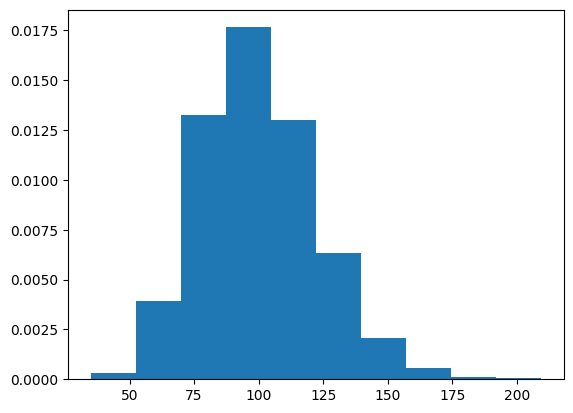

In [137]:
def gama_exp(k, lam, M):
  amostra = []
  for i in range(M):
    valor = []
    for j in range(k):
      x = (-1/lam) * np.log(np.random.uniform())
      valor.append(x)
    amostra.append(sum(valor))

  return amostra

dados = gama_exp(20, 1/5, 10_000)

plt.hist(dados, density=True)
plt.show()

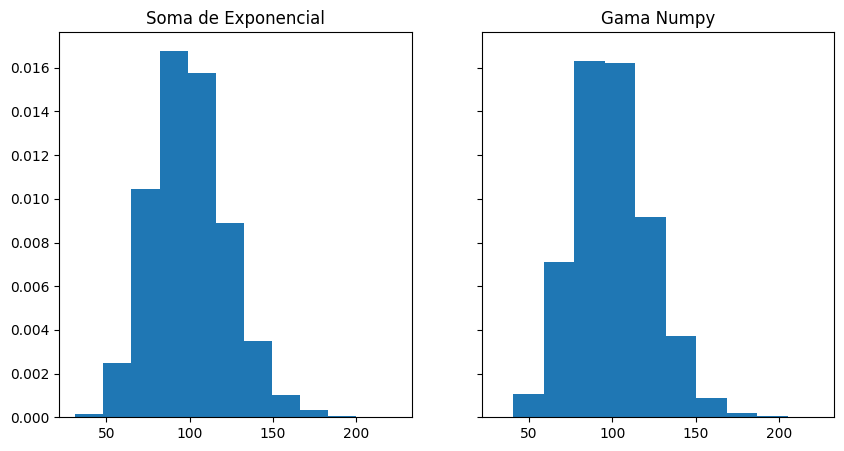

In [138]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

dados = gama_exp(20, 1/5, 10_000)

ax[0].hist(dados, density=True)
ax[0].set_title('Soma de Exponencial')

num = np.random.gamma(20, 5, 10_000)

ax[1].hist(num, density=True)
ax[1].set_title('Gama Numpy')

plt.show()

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [139]:
def f_gama(x, alpha, beta):
  return (beta**alpha)/(math.gamma(alpha)) * x**(alpha-1) * np.exp(-beta * x)

def g_gama(x, lam):
  return lam*np.exp(-lam*x)


In [140]:
alpha = 5
beta = 5
lam = beta/alpha

c = (beta**alpha)/(math.gamma(alpha) * lam) * ((alpha-1)/(beta-lam))**(alpha-1) * np.exp(-(alpha-1))

print(c)
print(1/c)

amostra = []

while len(amostra) < 10_000:
  u = np.random.uniform()
  y = (-1/lam) * np.log(np.random.uniform())

  if(u < f_gama(y, alpha, beta)/(c*g_gama(y, lam))):
    amostra.append(y)

valor = []
for x in np.linspace(0, 5, 10_000):
  valor.append(f_gama(x, alpha, beta))


2.384848813637263
0.41931379225454773


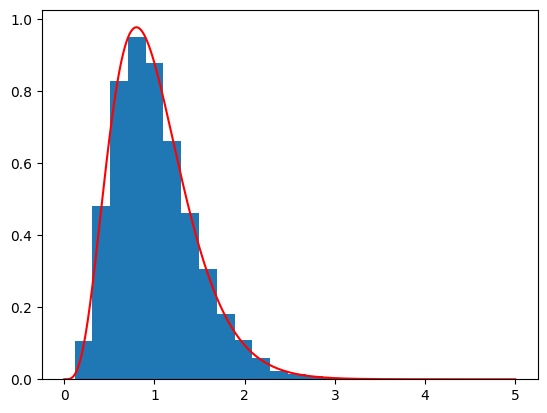

In [141]:
plt.hist(amostra, density=True, bins=20)
plt.plot(np.linspace(0, 5, 10_000), valor, color='red')
plt.show()

In [142]:
def gama(alpha, beta, M):
  lam = beta/alpha
  c = (beta**alpha)/(math.gamma(alpha) * lam) * ((alpha-1)/(beta-lam))**(alpha-1) * np.exp(-(alpha-1))
  amostra = []

  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1/lam) * np.log(np.random.uniform())

    if(u < f_gama(y, alpha, beta)/(c*g_gama(y, lam))):
      amostra.append(y)

  return amostra

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

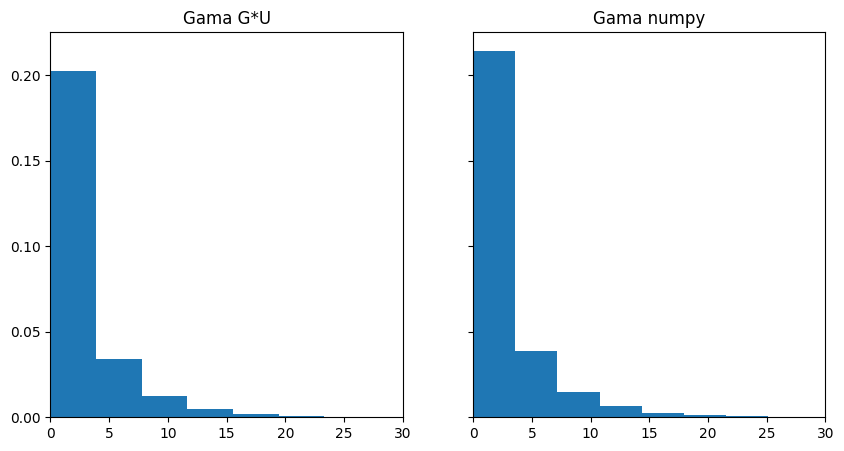

In [143]:
alpha = 0.5
beta = 5

G = gama(alpha+1, 1/beta, 10_000)
u = np.random.uniform(size=10_000)**(1/alpha)

amostra = G * u

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

ax[0].hist(amostra, density=True)
ax[0].set_title('Gama G*U')

num = np.random.gamma(alpha, beta, 10_000)

ax[1].hist(num, density=True)
ax[1].set_title('Gama numpy')

plt.xlim(0, 30)
plt.show()

# Distribuição Beta


## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [144]:
alpha = 5
beta = 5

def f_beta(x):
  return math.gamma(alpha + beta)/(math.gamma(alpha)*math.gamma(beta)) * x**(alpha-1) * (1-x)**(beta-1)

valor = []
for x in np.linspace(0, 1, 10_000):
  valor.append(f_beta(x))

c = np.max(valor)+0.05
print(c)

amostra = []

while len(amostra) < 10_000:
  u = np.random.uniform()
  y = np.random.uniform()

  if(u < f_beta(y)/c):
    amostra.append(y)


2.5109374015428108


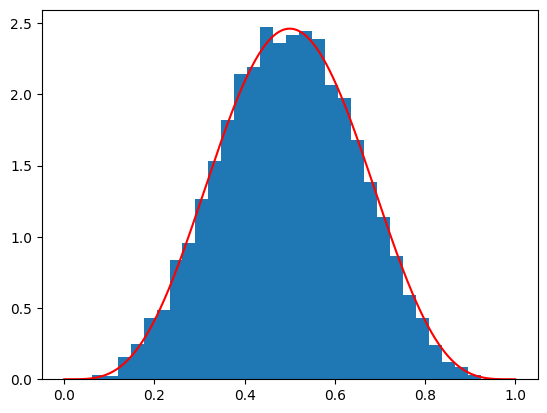

In [145]:
plt.hist(amostra, density=True, bins=30)
plt.plot(np.linspace(0, 1, 10_000), valor, color='red')
plt.show()

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

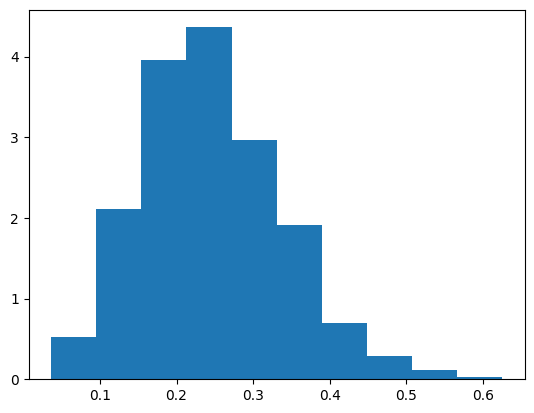

In [146]:
_alpha = 5
beta = 15

G1 = np.array(gama(alpha, 1, 1_000))
G2 = np.array(gama(beta, 1, 1_000))

amostra = G1/(G1+G2)

plt.hist(amostra, density=True)
plt.show()

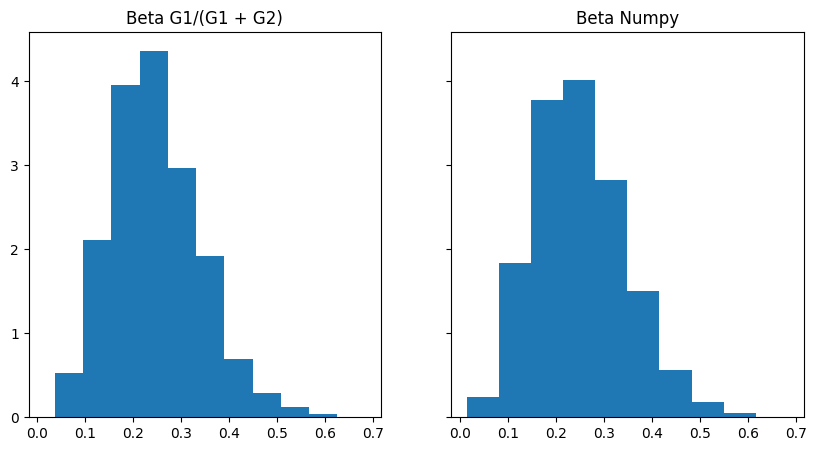

In [147]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

ax[0].hist(amostra, density=True)
ax[0].set_title('Beta G1/(G1 + G2)')

num = np.random.beta(5, 15, 10_000)

ax[1].hist(num, density=True)
ax[1].set_title('Beta Numpy')

plt.show()